In [4]:
import numpy as np
import matplotlib.pyplot as plt
import timeit

#1.Mathematical Definitions and evaluation counters
# We define global counters to accurately measure function evaluations
n_eval_f = 0    #number of f evaluations: counter for f(x0) evaluations
n_eval_df = 0    #number of df evaluations: counter for df(x0) evaluations (derivative of f)

#Non-linear function: f(x) = x^4 + 2x^3 - 7x^2 + 3
def f(x):
    global n_eval_f
    n_eval_f += 1    #increment f evaluation counter
    return x**4 + 2*x**3 - 7*x**2 + 3

#Analytical first derivative: f'(x) = 4x^3 + 6x^2 - 14x
def df(x):
    global n_eval_df
    n_eval_df += 1    #increment df evaluation counter
    return 4*x**3 + 6*x**2 - 14*x


#2.Implementation of Iterative Methods with evaluation tracking
#Newton-Raphson (N-R) Method
def newton_raphson(x0, tol=1e-4, maxit=15):
    errors = []
    evaluation_progress = []
    global n_eval_f, n_eval_df
    
    for i in range(maxit):
        fx = f(x0) #evaluation of f(x0) -> newton_eval_f += 1
        dfx = df(x0) #evaluation of df(x0) -> newton_eval_df += 1
        
        # We avoid division by zero (ZeroDivisionError)
        if dfx == 0:
            break
        x_next = x0 - fx / dfx #N-R iteration formula
        err = np.abs(x_next - x0) 
        errors.append(err)
        evaluation_progress.append(n_eval_f + n_eval_df)  # total flops per iteration
        
        if err < tol:
            break
        x0 = x_next
        
    return x_next, errors, evaluation_progress

#Secant Method
def secant(x0, x1, tol=1e-4, maxit=15):
    errors = []
    evaluation_progress = []
    global n_eval_f, n_eval_df
    
    #Two initial evaluations
    fx0 = f(x0)
    fx1 = f(x1)
    
    for i in range(maxit):
        denom = fx1 - fx0
        # We avoid division by zero (ZeroDivisionError)
        if denom == 0: 
            break
            
        x_next = x1 - (fx1 * (x1 - x0)) / denom
        err = np.abs(x_next - x1)
        errors.append(err)
        evaluation_progress.append(n_eval_f) #the secant method only uses evaluations of f(x) (total flops per iteration)
        
        if err < tol:
            break
            
        #We update the variables and reuse the evaluated function value
        x0, x1 = x1, x_next
        fx0 = fx1
        fx1 = f(x1)  #only 1 new evaluation per step
        
    return x_next, errors, evaluation_progress


#3. Single run comparison for the common positive root x* ~= 1.6180...
#Execution Parameters
tol = 1e-4
maxit = 15

#Newton-Raphson run starting from the initial approximation x0 = 1.4
n_eval_f, n_eval_df = 0, 0
sol_NR, err_NR, evaluations_NR = newton_raphson(1.4, tol, maxit)
total_evaluations_NR = n_eval_f + n_eval_df    #evaluations of f(x0) + evaluations of df(x0) = total flops

#Secant method run starting from the initial approximations x0 = 1.4, x1 = 1.5
n_eval_f, n_eval_df = 0, 0
sol_secant, err_secant, evaluations_secant = secant(1.4, 1.5, tol, maxit)
total_evaluations_secant = n_eval_f    #the secant method does not use the derivative of f


#4. Accurate CPU execution time benchmark (timeit)
#We execute 20,000 iterations to measure reliable execution time in microseconds
num_runs = 20000

timer_NR= timeit.timeit(lambda: newton_raphson(1.4, tol, maxit), number=num_runs)
mean_time_NR= (timer_NR / num_runs)*1e6  #converted to microseconds (μs)

timer_secant= timeit.timeit(lambda: secant(1.4, 1.5, tol, maxit), number=num_runs)
mean_time_secant= (timer_secant / num_runs)*1e6   #converted to microseconds (μs)


#5. Formatted output and metrics table
print("-" * 90)
print("Computational cost comparison: Newton-Raphson (N-R) method vs Secant method")
print("Target Equation: f(x) = x⁴ + 2x³ - 7x² + 3 = 0")
print("Tolerance= 10^-4 (1e-4)")
print("-" * 90)
print(f"{'Metric':<35} | {'Newton-Raphson (N-R)':<25} | {'Secant Method':<25}")
print("-" * 90)
print(f"{'Initial Estimate(s)':<35} | {'x0 = 1.4':<25} | {'x0=1.4, x1=1.5':<25}")
print("-" * 90)
print(f"{'Computed root (x*)':<35} | {sol_NR:<25.4f} | {sol_secant:<25.4f}")
print(f"{'Iterations to converge':<35} | {len(err_NR):<25d} | {len(err_secant):<25d}")
print(f"{'Function Evaluations (f + f\')':<35} | {total_evaluations_NR:<25d} | {total_evaluations_secant:<25d}")
print(f"{'Theoretical flops cost':<35} | {'10*k':<25} | {'7*k':<25}")
print(f"{'Final Error (e_last)':<35} | {f'{err_NR[-1]:.4e} ({err_NR[-1]:.5f})':<25} | {f'{err_secant[-1]:.4e} ({err_secant[-1]:.7f})':<25}")
print(f"{'Execution Time (timeit)':<35} | {f'{mean_time_NR:.2f} µs':<25} | {f'{mean_time_secant:.2f} µs':<25}")


------------------------------------------------------------------------------------------
Computational cost comparison: Newton-Raphson (N-R) method vs Secant method
Target Equation: f(x) = x⁴ + 2x³ - 7x² + 3 = 0
Tolerance= 10^-4 (1e-4)
------------------------------------------------------------------------------------------
Metric                              | Newton-Raphson (N-R)      | Secant Method            
------------------------------------------------------------------------------------------
Initial Estimate(s)                 | x0 = 1.4                  | x0=1.4, x1=1.5           
------------------------------------------------------------------------------------------
Computed root (x*)                  | 1.6180                    | 1.6180                   
Iterations to converge              | 5                         | 6                        
Function Evaluations (f + f')       | 10                        | 7                        
Theoretical flops cost       

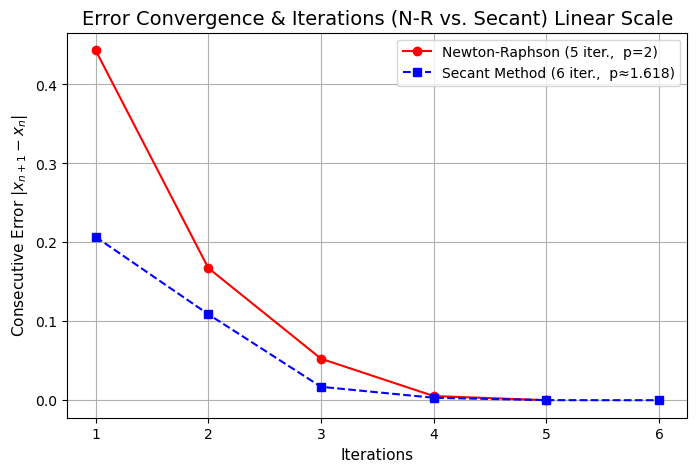

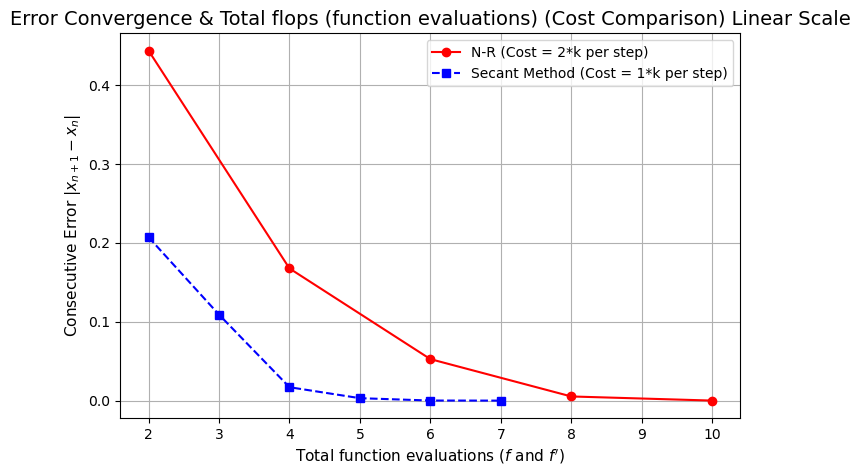

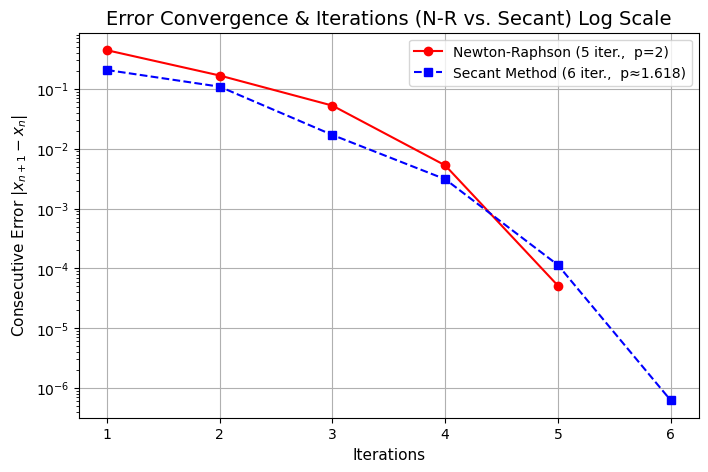

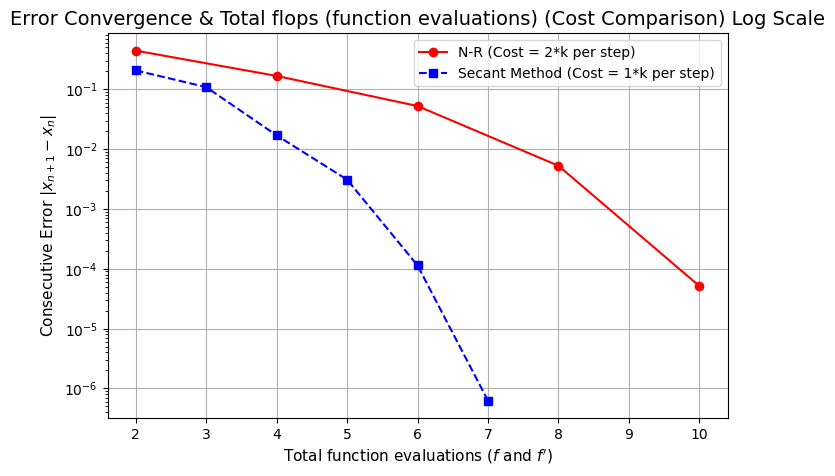

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import timeit

#1.Mathematical Definitions and evaluation counters
# We define global counters to accurately measure function evaluations
n_eval_f = 0    #number of f evaluations: counter for f(x0) evaluations
n_eval_df = 0    #number of df evaluations: counter for df(x0) evaluations (derivative of f)

#Non-linear function: f(x) = x^4 + 2x^3 - 7x^2 + 3
def f(x):
    global n_eval_f
    n_eval_f += 1    #increment f evaluation counter
    return x**4 + 2*x**3 - 7*x**2 + 3

#Analytical first derivative: f'(x) = 4x^3 + 6x^2 - 14x
def df(x):
    global n_eval_df
    n_eval_df += 1    #increment df evaluation counter
    return 4*x**3 + 6*x**2 - 14*x


#2.Implementation of Iterative Methods with evaluation tracking
#Newton-Raphson (N-R) Method
def newton_raphson(x0, tol=1e-4, maxit=15):
    errors = []
    evaluation_progress = []
    global n_eval_f, n_eval_df
    
    for i in range(maxit):
        fx = f(x0) #evaluation of f(x0) -> newton_eval_f += 1
        dfx = df(x0) #evaluation of df(x0) -> newton_eval_df += 1
        
        # We avoid division by zero (ZeroDivisionError)
        if dfx == 0:
            break
        x_next = x0 - fx / dfx #N-R iteration formula
        err = np.abs(x_next - x0) 
        errors.append(err)
        evaluation_progress.append(n_eval_f + n_eval_df)  # total flops per iteration
        
        if err < tol:
            break
        x0 = x_next
        
    return x_next, errors, evaluation_progress

#Secant Method
def secant(x0, x1, tol=1e-4, maxit=15):
    errors = []
    evaluation_progress = []
    global n_eval_f, n_eval_df
    
    #Two initial evaluations
    fx0 = f(x0)
    fx1 = f(x1)
    
    for i in range(maxit):
        denom = fx1 - fx0
        # We avoid division by zero (ZeroDivisionError)
        if denom == 0: 
            break
            
        x_next = x1 - (fx1 * (x1 - x0)) / denom
        err = np.abs(x_next - x1)
        errors.append(err)
        evaluation_progress.append(n_eval_f) #the secant method only uses evaluations of f(x) (total flops per iteration)
        
        if err < tol:
            break
            
        #We update the variables and reuse the evaluated function value
        x0, x1 = x1, x_next
        fx0 = fx1
        fx1 = f(x1)  #only 1 new evaluation per step
        
    return x_next, errors, evaluation_progress


#3. Single run comparison for the common positive root x* ~= 1.6180...
#Execution Parameters
tol = 1e-4
maxit = 15

#Newton-Raphson run starting from the initial approximation x0 = 1.4
n_eval_f, n_eval_df = 0, 0
sol_NR, err_NR, evaluations_NR = newton_raphson(1.4, tol, maxit)
total_evaluations_NR = n_eval_f + n_eval_df    #evaluations of f(x0) + evaluations of df(x0) = total flops

#Secant method run starting from the initial approximations x0 = 1.4, x1 = 1.5
n_eval_f, n_eval_df = 0, 0
sol_secant, err_secant, evaluations_secant = secant(1.4, 1.5, tol, maxit)
total_evaluations_secant = n_eval_f    #the secant method does not use the derivative of f


#4. Accurate CPU execution time benchmark (timeit)
#We execute 20,000 iterations to measure reliable execution time in microseconds
num_runs = 20000

timer_NR= timeit.timeit(lambda: newton_raphson(1.4, tol, maxit), number=num_runs)
mean_time_NR= (timer_NR / num_runs)*1e6  #converted to microseconds (μs)

timer_secant= timeit.timeit(lambda: secant(1.4, 1.5, tol, maxit), number=num_runs)
mean_time_secant= (timer_secant / num_runs)*1e6   #converted to microseconds (μs)

#6. Comparative Visualizations
#plot 1: Error & Iterations (Linear Scale)
plt.figure(figsize=(8, 5))
iterations_NR = range(1, len(err_NR) + 1)
iterations_secant = range(1, len(err_secant) + 1)
plt.plot(iterations_NR, err_NR, 'ro-', label=f'Newton-Raphson (5 iter.,  p=2)')    # 'ro-': red circles and a solid line
plt.plot(iterations_secant, err_secant, 'bs--', label=f'Secant Method (6 iter.,  p≈1.618)') #'bs--': blue squares and a dashed line
plt.xlabel('Iterations', fontsize=11)
plt.ylabel('Consecutive Error $|x_{n+1} - x_n|$', fontsize=11)
plt.title('Error Convergence & Iterations (N-R vs. Secant) Linear Scale', fontsize=14)
plt.xticks(range(1, max(len(err_NR), len(err_secant)) + 1))
plt.grid()
plt.legend()
plt.show()

#plot 2: Error & Function Evaluations (Computational cost) (Linear Scale)
plt.figure(figsize=(8, 5))
plt.plot(evaluations_NR, err_NR, 'ro-', label='N-R (Cost = 2*k per step)')
plt.plot(evaluations_secant, err_secant, 'bs--', label='Secant Method (Cost = 1*k per step)')
plt.xlabel('Total function evaluations ($f$ and $f\'$)', fontsize=11)
plt.ylabel('Consecutive Error $|x_{n+1} - x_n|$', fontsize=11)
plt.title('Error Convergence & Total flops (function evaluations) (Cost Comparison) Linear Scale', fontsize=14)
plt.grid()
plt.legend()
plt.show()

#plot 3: Error & Iterations (Log Scale)
plt.figure(figsize=(8, 5))
iterations_NR = range(1, len(err_NR) + 1)
iterations_secant = range(1, len(err_secant) + 1)
plt.plot(iterations_NR, err_NR, 'ro-', label=f'Newton-Raphson (5 iter.,  p=2)')    # 'ro-': red circles and a solid line
plt.plot(iterations_secant, err_secant, 'bs--', label=f'Secant Method (6 iter.,  p≈1.618)') #'bs--': blue squares and a dashed line
plt.yscale('log')
plt.xlabel('Iterations', fontsize=11)
plt.ylabel('Consecutive Error $|x_{n+1} - x_n|$', fontsize=11)
plt.title('Error Convergence & Iterations (N-R vs. Secant) Log Scale', fontsize=14)
plt.xticks(range(1, max(len(err_NR), len(err_secant)) + 1))
plt.grid()
plt.legend()
plt.show()

#plot 4: Error & Function Evaluations (Computational cost) (Log Scale)
plt.figure(figsize=(8, 5))
plt.plot(evaluations_NR, err_NR, 'ro-', label='N-R (Cost = 2*k per step)')
plt.plot(evaluations_secant, err_secant, 'bs--', label='Secant Method (Cost = 1*k per step)')
plt.yscale('log')
plt.xlabel('Total function evaluations ($f$ and $f\'$)', fontsize=11)
plt.ylabel('Consecutive Error $|x_{n+1} - x_n|$', fontsize=11)
plt.title('Error Convergence & Total flops (function evaluations) (Cost Comparison) Log Scale', fontsize=14)
plt.grid()
plt.legend()
plt.show()